# Работа с изображениями, часть 2
(использование нейронных сетей)

Семинарист: [Федорова Валерия Сергеевна](https://www.hse.ru/org/persons/510438167)

Скрипт подготовлен по материалам: [Проворовой (Радыгиной) Анны Александровны](https://www.hse.ru/staff/provorovaaa/)

# Нейронные сети и сверточные нейронные сети

## Что такое нейронная сеть?

Нейронная сеть (Neural Network) — математическая модель машинного обучения, которая обучается находить закономерности в данных и использовать их для решения задач.

В отличие от классического подхода, где признаки часто определяются исследователем вручную, нейронная сеть может самостоятельно извлекать полезные признаки непосредственно из изображений.

Например, при распознавании животных нам не нужно заранее программировать правила вида:
- у кенгуру длинные задние лапы;
- у капибары характерная форма морды;
- у животных разная форма ушей.
Сеть учится находить отличительные визуальные признаки на примере множества изображений.

### Как устроена нейронная сеть?

Нейронная сеть состоит из взаимосвязанных слоёв:
- Входной слой (Input Layer) — получает исходные данные, в нашем случае изображение.
- Скрытые слои (Hidden Layers) — последовательно обрабатывают данные и извлекают признаки.
- Выходной слой (Output Layer) — формирует итоговое предсказание.

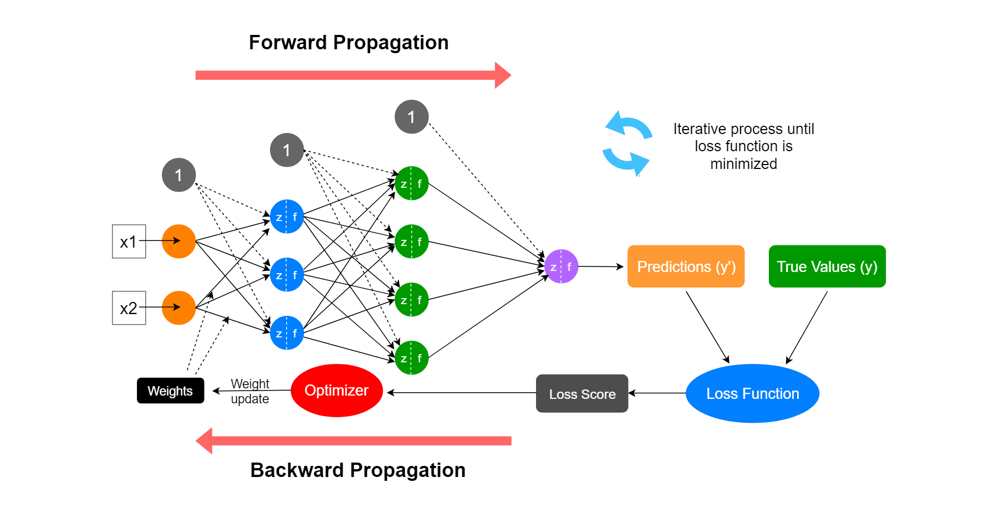

### Как работает отдельный нейрон?

Искусственный нейрон выполняет несколько операций:
1. Получает входные значения.
2. Умножает их на обучаемые веса (weights).
3. Складывает результаты и добавляет смещение (bias).
4. Применяет функцию активации (activation function).
5. Передаёт результат следующему слою.

**Важно:** веса и смещения — обучаемые параметры. В процессе обучения сеть подбирает их значения, чтобы уменьшать ошибки предсказаний.

## Как нейронная сеть обучается?

Обучение представляет собой повторяющийся процесс:
1. Прямое распространение (Forward propagation) — изображение проходит через сеть, формируется предсказание.
2. Функция потерь (Loss function) — функция потерь оценивает, насколько предсказание отличается от правильного ответа.
3. Обратное распространение ошибки (Backpropagation) — рассчитываются градиенты, показывающие, как изменение параметров влияет на ошибку.
4. Оптимизатор (Optimizer) — обновляет веса и смещения, чтобы уменьшить ошибку.

Основные термины:

| Термин |	Значение |
|------- | --------- |
| Эпоха (Epoch) |	Один полный проход по обучающей выборке |
| Батч (Batch) |	Группа изображений, обрабатываемая за одну итерацию |
| Размер батча (Batch size) |	Количество изображений в батче |
| Итерация (Iteration) |	Один шаг обработки батча и обновления параметров |
| Learning rate |	Скорость изменения весов при обучении (величина шага, с которым оптимизатор меняет веса) |
| Loss |	Значение функции потерь |

Например, если у нас 1 000 изображений и batch size = 32, одна эпоха будет состоять из 32 итераций: 31 батч по 32 изображения и последний из 8 изображений.

## Как компьютер представляет изображение?

Компьютер не воспринимает изображение как капибару или кенгуру. Для него это набор числовых значений — пикселей.

Каждый пиксель цветного RGB-изображения содержит три значения:
- R (Red) — интенсивность красного;
- G (Green) — интенсивность зелёного;
- B (Blue) — интенсивность синего.

Обычно каждое значение находится в диапазоне от 0 до 255.

### Что такое тензор?

Тензор (Tensor) — многомерный числовой массив, используемый для хранения и обработки данных в нейронных сетях.

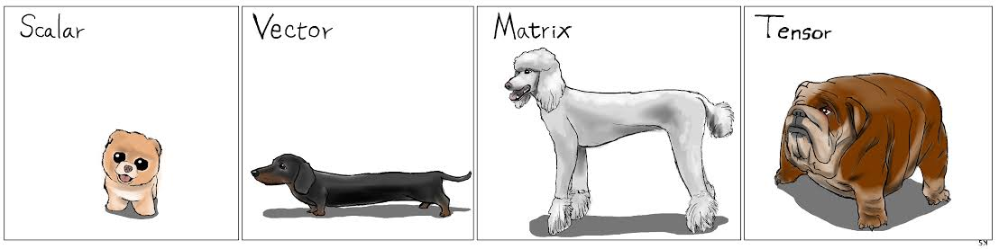

Векторы и матрицы также являются частными случаями тензоров.

Представление изображения:

Цветное изображение можно представить тензором:

$$
H \times W \times C
$$

где:
- $H$ — высота изображения;
- $W$ — ширина;
- $C$ — количество цветовых каналов (для RGB — 3).

Например, изображение размером 224 × 224 пикселя:

$$
224 \times 224 \times 3
$$

Если мы одновременно передаём в сеть 32 изображения, получаем четырёхмерный тензор:

$$
32 \times 224 \times 224 \times 3
$$

Первая размерность — количество изображений в батче.

В таком виде изображения поступают в нейронную сеть для обработки.

## Почему для изображений используют CNN?

Можно было бы передавать изображение в обычную полносвязную нейронную сеть, предварительно преобразовав его в вектор.

Однако такой подход имеет недостатки:
- теряется явная пространственная структура изображения;
- получается очень большое количество входных значений;
- полносвязной сети сложно эффективно находить локальные визуальные признаки.

Например, изображение размером 224 × 224 × 3 содержит 150 528 числовых значений. Если подключить их к полносвязному слою из 1 000 нейронов, потребуется более 150 миллионов весов только для этого слоя.

**Сверточная нейронная сеть (Convolutional Neural Network, CNN)** — архитектура нейронной сети, специально предназначенная для обработки изображений и извлечения из них пространственных признаков.

Главное отличие CNN — использование свёрточных слоёв, которые анализируют небольшие участки изображения с помощью обучаемых фильтров.

## Как работает свёрточный слой?

**Свёрточный слой (Convolutional Layer)** — слой, который применяет набор фильтров к изображению и формирует карты признаков.

**Фильтр (Filter / Kernel)** — небольшая матрица обучаемых значений, которая перемещается по изображению и выполняет вычисления с его локальными участками.

Например, фильтр 3 × 3 анализирует участки изображения размером 3 × 3 пикселя.

При каждом перемещении:
1. Значения фильтра перемножаются с соответствующими значениями участка изображения.
2. Результаты суммируются.
3. Полученное значение записывается в новую матрицу.

В результате формируется **карта признаков (Feature Map)** — представление того, насколько сильно фильтр реагирует на различные участки изображения.

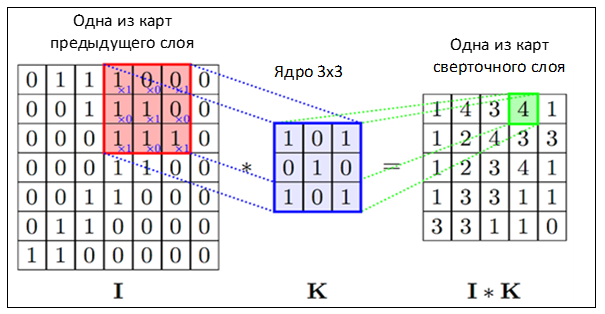

В процессе обучения сеть самостоятельно подбирает значения фильтров. Одни могут реагировать на границы, другие — на текстуры и другие визуальные особенности.

Основные параметры свёрточного слоя
| Параметр |	Что означает |
| -------- | ------------- |
| filters |	Количество используемых фильтров |
| kernel_size |	Размер фильтра |
| strides |	Шаг перемещения фильтра |
| padding |	Добавление границ для управления размером результата |

Например:

Conv2D(filters=32, kernel_size=(3, 3))

Означает, что слой использует 32 обучаемых фильтра размером 3 × 3.

## Другие основные слои CNN

1. ReLU (функция активации)

$$
ReLU(x)=\max(0,x)
$$

Заменяет отрицательные значения на ноль, положительные оставляет без изменений. Добавляет нелинейность, необходимую для обучения сложным закономерностям.

2. MaxPooling2D (слой подвыборки)

Уменьшает пространственный размер карт признаков, выбирая максимальное значение из каждого локального участка.

Это позволяет сократить объём вычислений и сохранить наиболее выраженные признаки.

3. Flatten (выравнивание)

Преобразует многомерные карты признаков в одномерный вектор.

Например:
$$
7\times7\times64 \rightarrow 3136
$$

4. Dense (полносвязный слой)

Использует извлечённые признаки для формирования решения о классе изображения.

5. Sigmoid (выходная функция активации)

$$
\sigma(x)=\frac{1}{1+e^{-x}}
$$

Преобразует результат в число от 0 до 1. Удобна для бинарной классификации, когда необходимо получить оценку вероятности принадлежности к одному из двух классов.

## Как CNN распознаёт изображение?

В процессе обработки изображения сеть постепенно формирует всё более сложные признаки:
- Ранние слои: границы, линии, цветовые переходы.
- Промежуточные слои: текстуры, формы, сочетания простых признаков.
- Глубокие слои: сложные комбинации признаков, полезные для распознавания объектов.

Например, при обучении на фотографиях капибар и кенгуру CNN учится находить визуальные закономерности, которые помогают различать эти два класса, например, длину конечностей, ушей, цвет и текстура шерсти и другие.

При этом мы не задаём фильтрам вручную, какие именно части животных искать: сеть обучает их самостоятельно.

## Итоговая архитектура CNN

Теперь объединим рассмотренные элементы в единую последовательность.

| Элемент |	Назначение |
| ------- | ---------- |
| Input |	Получение изображения |
| Conv2D |	Извлечение признаков с помощью фильтров |
| ReLU |	Добавление нелинейности |
| MaxPooling2D |	Уменьшение размерности карт признаков |
| Flatten |	Преобразование карт признаков в вектор |
| Dense |	Классификация изображения |
| Sigmoid |	Получение оценки вероятности класса |

Таким образом, CNN сначала извлекает признаки из изображения, а затем использует их для определения класса.

На следующем этапе мы построим собственную сверточную нейронную сеть и обучим её отличать капибар от кенгуру.

Для построения CNN используем TensorFlow.

**TensorFlow** — это открытая платформа с открытым исходным кодом, разработанная Google, предназначенная для построения и обучения моделей машинного и глубокого обучения. Она поддерживает гибкое создание вычислительных графов, автоматическое дифференцирование и масштабируемое выполнение на CPU, GPU и TPU. Библиотека **Keras**, интегрированная в TensorFlow как `tf.keras`, предоставляет высокоуровневый, интуитивно понятный API для быстрой разработки нейронных сетей, что делает TensorFlow популярным выбором как в исследованиях, так и в промышленности.

Перед началом: убедитесь, что у Вас есть доступ к GPU.

Если Вы используете Google Colab, то перейдите "Среда выполнения" -> "Сменить среду выполнения" -> "Т4 GPU" (ГРАФИЧЕСКИЙ ПРОЦЕССОР Т4).

Если Вы работаете на своём компьютере, то убедитесь, что у вас есть видеокарта NVidia и на неё установлены соответствующие драйверы.

# Обучим свою нейросеть, которая будет классифицировать изображения на капибар и кенгуру

## Загрузим данные

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Путь к папке с датасетом
DATA_DIR = '/content/drive/MyDrive/IDlab/машинное_обучение/data_sem_9'

Если не фиксировать случайные состояния, при каждом запуске могут получаться немного разные выборки и результаты обучения. SEED = 42 помогает сделать эксперименты воспроизводимыми: при одинаковых данных, настройках и окружении результаты будут повторяться с большей вероятностью.

In [ ]:
import os
import random
import numpy as np
import tensorflow as tf

# Фиксируем случайные состояния для воспроизводимости результатов
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Дополнительно фиксируем случайность на уровне операций TensorFlow
os.environ['PYTHONHASHSEED'] = str(SEED)

print(f'Random seed: {SEED}')

Random seed: 42


## Импорт библиотек

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
# Находим папки с классами
data_path = Path(DATA_DIR)

class_names = sorted([
    folder.name for folder in data_path.iterdir()
    if folder.is_dir()
])

print('Классы:', class_names)

# Формируем таблицу с изображениями и метками
image_paths = []
labels = []

extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

for label, class_name in enumerate(class_names):
    class_folder = data_path / class_name

    for image_path in class_folder.rglob('*'):
        if image_path.suffix.lower() in extensions:
            image_paths.append(str(image_path))
            labels.append(label)

df = pd.DataFrame({
    'filepath': image_paths,
    'label': labels
})

print('Всего изображений:', len(df))
print('\nКоличество изображений по классам:')
print(df['label'].map(dict(enumerate(class_names))).value_counts())

Классы: ['capybara', 'kangaroo']
Всего изображений: 293

Количество изображений по классам:
label
capybara    152
kangaroo    141
Name: count, dtype: int64


## Разделим данные на обучающую, валидационную и тестовую выборки

Мы разделяем данные на три части, потому что хотим не просто добиться хороших результатов на фотографиях, которые модель уже видела, а научить её распознавать новые изображения.

| Выборка |	Для чего нужна |
| ------- | -------------- |
| Train |	На этих изображениях модель обучается: рассчитывает ошибки и обновляет веса |
| Validation |	Проверяем качество во время разработки модели, например, после каждой эпохи |
| Test |	Финальная проверка качества на изображениях, которые не использовались при обучении и настройке |

In [ ]:
# Сначала отделяем 70% для обучения и 30% для остальных выборок
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=42
)

# Оставшиеся 30% делим пополам: 15% validation и 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=42
)

print('Train:', len(train_df))
print('Validation:', len(val_df))
print('Test:', len(test_df))

Train: 205
Validation: 44
Test: 44


In [ ]:
for name, part in [
    ('Train', train_df),
    ('Validation', val_df),
    ('Test', test_df)
]:
    print(f'\n{name}:')
    print(part['label'].map(dict(enumerate(class_names))).value_counts())


Train:
label
capybara    106
kangaroo     99
Name: count, dtype: int64

Validation:
label
capybara    23
kangaroo    21
Name: count, dtype: int64

Test:
label
capybara    23
kangaroo    21
Name: count, dtype: int64


## Подготовка изображений

Нейросеть должна получать изображения одинакового размера. Поэтому приведём все фотографии к размеру 224 × 224 пикселей.

Также объединим изображения в батчи по 32 штуки.

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.ensure_shape(image, [IMG_SIZE, IMG_SIZE, 3])

    return image, label

def create_dataset(dataframe, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe['filepath'].values,
        dataframe['label'].values
    ))

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

In [ ]:
train_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>

### Рассмотрим несколько изображений из обучающей выборки

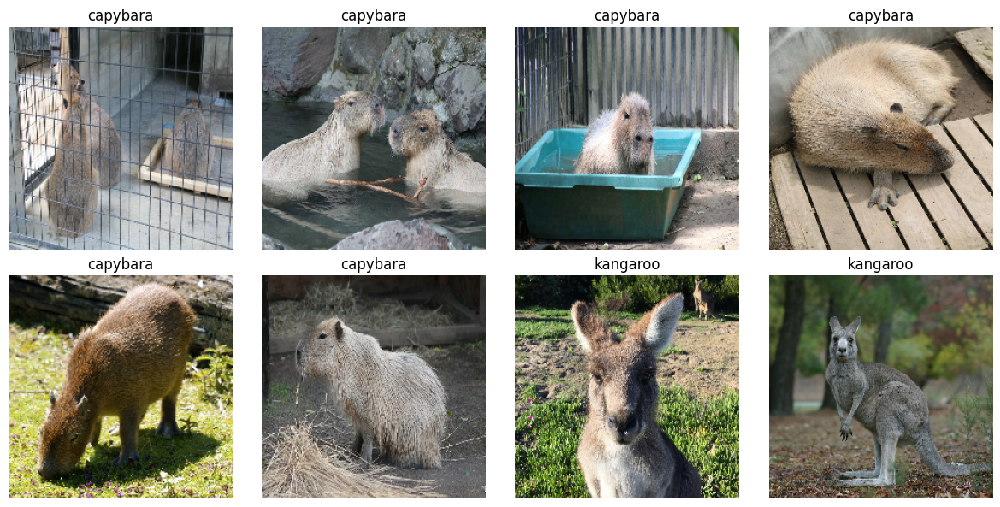

In [ ]:
plt.figure(figsize=(12, 6))

for images, labels_batch in train_ds.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[int(labels_batch[i])])
        plt.axis('off')

plt.tight_layout()
plt.show()

## Создание нейронной сети

Создадим простую сверточную нейронную сеть (CNN).

В её архитектуре будут использоваться:

- `Conv2D` — свёрточные слои для выделения признаков;
- `ReLU` — функция активации;
- `MaxPooling2D` — уменьшение пространственного размера карт признаков;
- `Flatten` — преобразование карт признаков в одномерный вектор;
- `Dense` — полносвязный слой;
- `Dropout` — регуляризация, помогающая снизить риск переобучения;
- `Sigmoid` — получение вероятности принадлежности к положительному классу.

In [ ]:
import tensorflow as tf

from tensorflow.keras import layers, models

# Параметры модели
IMG_SIZE = (224, 224)  # Размер изображений
BATCH_SIZE = 32        # Количество изображений в одном батче

In [ ]:
model = tf.keras.Sequential([

    # Входной слой: изображение размером 224 × 224 с тремя цветовыми каналами RGB
    tf.keras.layers.Input(shape=(*IMG_SIZE, 3)),

    # Нормализация входных данных:
    # переводим значения пикселей из диапазона [0, 255] в [0, 1]
    tf.keras.layers.Rescaling(1./255),

    # Первый свёрточный блок:
    # 32 фильтра размером 3 × 3 выделяют простые признаки изображения
    # (границы, линии, текстуры)
    tf.keras.layers.Conv2D(32, 3, activation='relu'),

    # MaxPooling уменьшает пространственный размер карт признаков в 2 раза
    tf.keras.layers.MaxPooling2D(),

    # Второй свёрточный блок:
    # 64 фильтра позволяют выделять более сложные сочетания признаков
    tf.keras.layers.Conv2D(64, 3, activation='relu'),

    tf.keras.layers.MaxPooling2D(),

    # Третий свёрточный блок:
    # 128 фильтров позволяют формировать ещё более сложные признаки
    tf.keras.layers.Conv2D(128, 3, activation='relu'),

    # Глобальное усреднение:
    # для каждой карты признаков рассчитывается среднее значение
    # по всем пространственным позициям
    # В результате вместо большого набора значений получаем 128 чисел
    tf.keras.layers.GlobalAveragePooling2D(),

    # Выходной слой для бинарной классификации:
    # один нейрон с Sigmoid выдаёт вероятность принадлежности к классу 1
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Выводим архитектуру и количество параметров модели
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

## Компиляция модели

Перед обучением зададим оптимизатор, функцию потерь и метрики качества.

- `optimizer='adam'` — алгоритм оптимизации, который обновляет веса модели.
- `loss='binary_crossentropy'` — функция потерь для бинарной классификации.
- `accuracy` — доля правильных предсказаний.
- `precision` — доля правильных положительных предсказаний среди всех положительных предсказаний модели.
- `recall` — доля объектов положительного класса, которые модель смогла обнаружить.

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

## Обучим модель

Добавим `EarlyStopping`: если качество на валидационной выборке перестанет улучшаться, обучение остановится. При этом будут восстановлены веса лучшей эпохи.

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stopping]
)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 12s 704ms/step - accuracy: 0.4780 - loss: 0.6966 - precision: 0.3750 - recall: 0.1212 - val_accuracy: 0.5227 - val_loss: 0.6903 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.4634 - loss: 0.6943 - precision: 0.4604 - recall: 0.6465 - val_accuracy: 0.4773 - val_loss: 0.6942 - val_precision: 0.4773 - val_recall: 1.0000
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - accuracy: 0.4829 - loss: 0.6931 - precision: 0.4759 - recall: 0.6970 - val_accuracy: 0.5455 - val_loss: 0.6901 - val_precision: 1.0000 - val_recall: 0.0476
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - accuracy: 0.5268 - loss: 0.6886 - precision: 0.7500 - recall: 0.0303 - val_accuracy: 0.5455 - val_loss: 0.6851 - val_precision: 1.0000 - val_recall: 0.0476
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - accuracy: 0.5756 - loss: 0.6805 - precision: 0.8750 - recall: 0.1414 - val_accuracy: 0.5455 - val_loss: 0.685

## Анализ процесса обучения

Посмотрим, как изменялись значения функции потерь и Accuracy на обучающей и валидационной выборках.

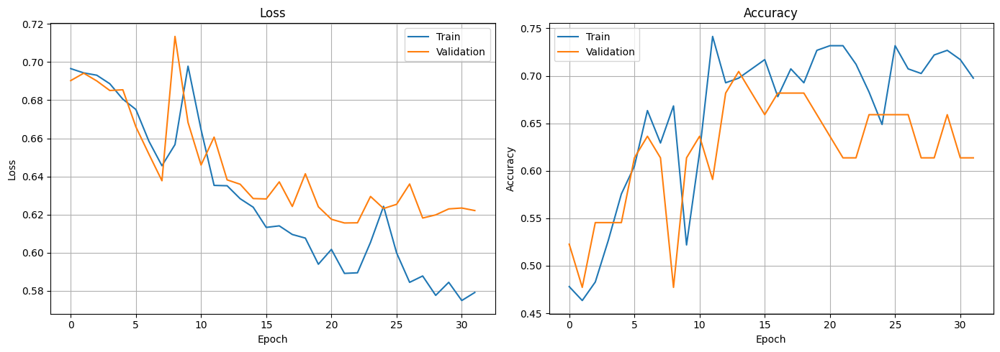

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Функция потерь
axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid()

# Accuracy
axes[1].plot(history.history['accuracy'], label='Train')
axes[1].plot(history.history['val_accuracy'], label='Validation')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

## Оценка качества на тестовой выборке

In [ ]:
test_loss, test_accuracy, test_precision, test_recall = model.evaluate(test_ds)

print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')
print(f'Test Precision: {test_precision:.4f}')
print(f'Test Recall: {test_recall:.4f}')

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7273 - loss: 0.6210 - precision: 0.7647 - recall: 0.6190 
Test Loss: 0.6210
Test Accuracy: 0.7273
Test Precision: 0.7647
Test Recall: 0.6190


In [ ]:
# Вероятности принадлежности к классу 1
y_prob = model.predict(test_ds).ravel()

# Преобразуем вероятности в метки классов
y_pred = (y_prob >= 0.5).astype(int)

# Истинные метки
y_true = test_df['label'].values

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 332ms/step


In [ ]:
print('Accuracy:', accuracy_score(y_true, y_pred))
print('Precision:', precision_score(y_true, y_pred, zero_division=0))
print('Recall:', recall_score(y_true, y_pred, zero_division=0))
print('F1-score:', f1_score(y_true, y_pred, zero_division=0))

Accuracy: 0.7272727272727273
Precision: 0.7647058823529411
Recall: 0.6190476190476191
F1-score: 0.6842105263157895


In [ ]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
display(report_df.round(3))

,precision,recall,f1-score,support
capybara,0.704,0.826,0.760,23.000
kangaroo,0.765,0.619,0.684,21.000
accuracy,0.727,0.727,0.727,0.727
macro avg,0.734,0.723,0.722,44.000
weighted avg,0.733,0.727,0.724,44.000


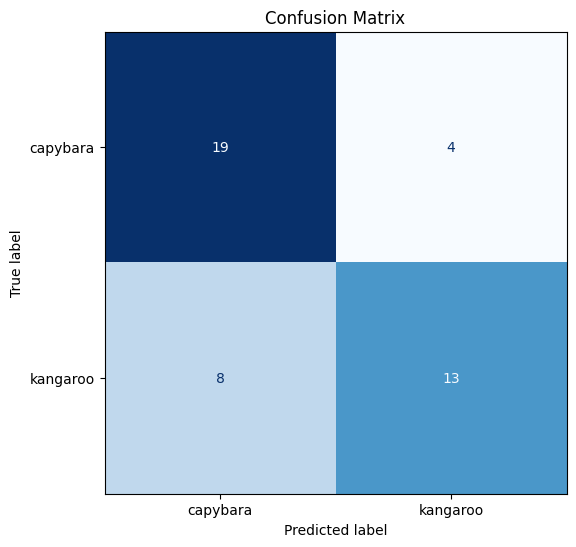

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(
    ax=ax,
    cmap='Blues',
    values_format='d',
    colorbar=False
)

plt.title('Confusion Matrix')
plt.show()

In [ ]:
results_df = test_df.copy().reset_index(drop=True)

results_df['true_label'] = y_true
results_df['pred_label'] = y_pred

# Вероятность именно предсказанного класса
results_df['confidence'] = np.where(
    y_pred == 1,
    y_prob,
    1 - y_prob
)

# Оставляем только ошибочные предсказания
errors_df = results_df[
    results_df['true_label'] != results_df['pred_label']
]

print('Всего ошибочных предсказаний:', len(errors_df))

Всего ошибочных предсказаний: 12


In [ ]:
for class_id, class_name in enumerate(class_names):

    # Изображения, которые на самом деле принадлежат текущему классу,
    # но модель отнесла их к другому классу
    class_errors = errors_df[
        errors_df['true_label'] == class_id
    ]

    print(f'\nОшибки для класса "{class_name}": {len(class_errors)}')

    # Показываем, к каким классам модель ошибочно отнесла изображения
    for pred_id, pred_name in enumerate(class_names):

        errors_to_class = class_errors[
            class_errors['pred_label'] == pred_id
        ]

        if len(errors_to_class) > 0:
            print(
                f'  → Ошибочно классифицированы как "{pred_name}": '
                f'{len(errors_to_class)}'
            )


Ошибки для класса "capybara": 4
  → Ошибочно классифицированы как "kangaroo": 4

Ошибки для класса "kangaroo": 8
  → Ошибочно классифицированы как "capybara": 8


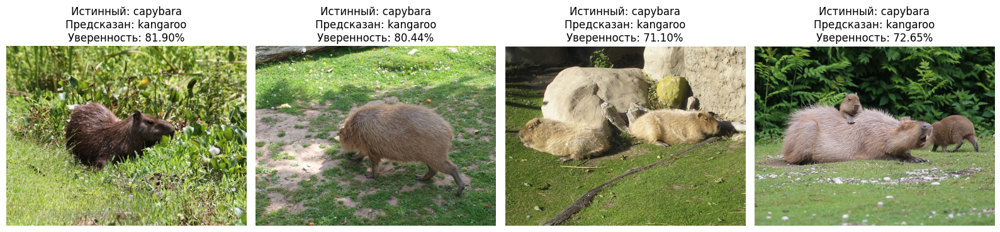

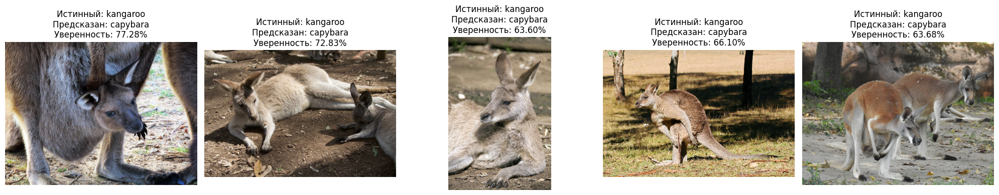

In [ ]:
for class_id, class_name in enumerate(class_names):

    class_errors = errors_df[
        errors_df['true_label'] == class_id
    ].head(5)

    if len(class_errors) == 0:
        print(f'Для класса {class_name} ошибок нет.')
        continue

    fig, axes = plt.subplots(
        1,
        len(class_errors),
        figsize=(4 * len(class_errors), 4)
    )

    if len(class_errors) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, class_errors.iterrows()):

        image = plt.imread(row['filepath'])
        ax.imshow(image)

        true_name = class_names[int(row['true_label'])]
        pred_name = class_names[int(row['pred_label'])]

        ax.set_title(
            f'Истинный: {true_name}\n'
            f'Предсказан: {pred_name}\n'
            f'Уверенность: {row["confidence"]:.2%}'
        )

        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Возьмем обученную VGG и дообучим под нашу задачу

## Чем VGG отличается от нашей CNN?

Наша нейросеть и VGG — это обе свёрточные нейронные сети (CNN), предназначенные для анализа изображений. Главное отличие — в архитектуре и способе обучения.

- Наша CNN

Мы самостоятельно создали архитектуру: выбрали количество свёрточных слоёв, фильтров и способ объединения признаков. Модель обучается с нуля и постепенно учится распознавать признаки капибар и кенгуру.

- VGG

Это заранее разработанная архитектура CNN. Она состоит из последовательности свёрточных слоёв с небольшими фильтрами 3×3 и слоёв MaxPooling. VGG имеет гораздо более глубокую структуру — например, VGG16 содержит 16 слоёв с обучаемыми параметрами.

## Что делает VGG?
Изначально VGG обучали на большом наборе изображений ImageNet, чтобы распознавать множество объектов. В нашей задаче мы можем использовать её как основу для классификации капибар и кенгуру.

Есть несколько основных подходов:
1. Обучение с нуля — инициализируем веса случайным образом и обучаем всю сеть на нашем датасете.
2. Дообучение всей модели — модель уже обучена на каком-то датасете, но мы хотим, чтобы она лучше выполняла именно нашу задачу, поэтому мы прогоняем полностью уже обученную модель на нашем датасете и корректируем веса на каждом слое.
2. Transfer Learning (перенос обучения) — берём VGG с уже обученными на ImageNet весами, заменяем классификационную часть под два наших класса и дообучаем модель.

Главная идея: вместо того чтобы учить нейросеть распознавать все визуальные признаки с нуля на небольшом датасете, мы используем знания, полученные при обучении на большом количестве изображений.

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Размер изображений
IMG_SIZE = (224, 224)

# Загружаем VGG16 с весами, предварительно обученными на ImageNet.
# include_top=False означает, что стандартную классификационную
# часть VGG16 мы не загружаем — вместо неё создадим свою.
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)

# Замораживаем все слои VGG16.
# На первом этапе их веса изменяться не будут.
base_model.trainable = False

# Создаём входной слой
inputs = Input(shape=(*IMG_SIZE, 3))

# Приводим изображения к формату, который ожидает VGG16.
# Важно: здесь не используем Rescaling(1./255),
# поскольку preprocess_input выполняет собственную предобработку.
x = tf.keras.layers.Lambda(preprocess_input)(inputs)

# Пропускаем изображения через предобученную VGG16
x = base_model(x, training=False)

# Усредняем карты признаков, полученные VGG16
x = GlobalAveragePooling2D()(x)

# Добавляем Dropout для снижения риска переобучения
x = Dropout(0.3)(x)

# Выходной слой для бинарной классификации:
# 0 — капибара, 1 — кенгуру
outputs = Dense(1, activation='sigmoid')(x)

# Собираем итоговую модель
vgg_model = Model(inputs, outputs)

# Компилируем модель
vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

# Посмотрим на архитектуру
vgg_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,201 (56.13 MB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
# Обучаем только новые слои классификатора.
# Слои VGG16 пока остаются замороженными.

history_vgg = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50
)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 814ms/step - accuracy: 0.4537 - loss: 6.7613 - precision: 0.0667 - recall: 0.0101 - val_accuracy: 0.4773 - val_loss: 2.5963 - val_precision: 0.3333 - val_recall: 0.0952
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 179ms/step - accuracy: 0.5122 - loss: 3.2862 - precision: 0.4933 - recall: 0.3737 - val_accuracy: 0.5682 - val_loss: 1.5647 - val_precision: 0.5357 - val_recall: 0.7143
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 177ms/step - accuracy: 0.5220 - loss: 2.9417 - precision: 0.5042 - recall: 0.6061 - val_accuracy: 0.6591 - val_loss: 1.5324 - val_precision: 0.5882 - val_recall: 0.9524
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 0.6293 - loss: 1.9701 - precision: 0.5906 - recall: 0.7576 - val_accuracy: 0.7045 - val_loss: 0.7863 - val_precision: 0.6250 - val_recall: 0.9524
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 174ms/step - accuracy: 0.7171 - loss: 1.3046 - precision: 0.6990 - recall: 0.7273 - val_accuracy: 0.9318 - val_loss: 0.3459 - val

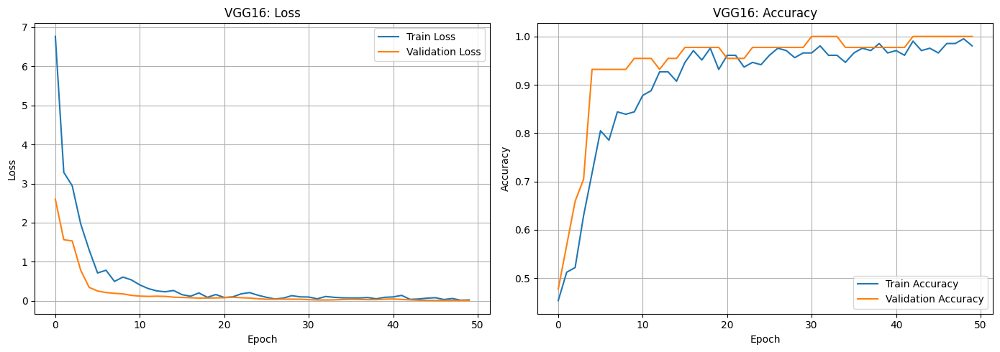

In [ ]:
import matplotlib.pyplot as plt

# Получаем историю обучения
history = history_vgg.history

# Создаём два графика
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График Loss
axes[0].plot(history['loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Validation Loss')
axes[0].set_title('VGG16: Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid()

# График Accuracy
axes[1].plot(history['accuracy'], label='Train Accuracy')
axes[1].plot(history['val_accuracy'], label='Validation Accuracy')
axes[1].set_title('VGG16: Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [ ]:
# Оцениваем модель на тестовой выборке
test_results = vgg_model.evaluate(test_ds, return_dict=True)

print('Результаты VGG16 на тестовой выборке:')

for metric, value in test_results.items():
    print(f'{metric}: {value:.4f}')

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 1.0000 - loss: 0.0022 - precision: 1.0000 - recall: 1.0000
Результаты VGG16 на тестовой выборке:
accuracy: 1.0000
loss: 0.0022
precision: 1.0000
recall: 1.0000


In [ ]:
# Получаем вероятности принадлежности к классу 1 (кенгуру)
y_prob_vgg = vgg_model.predict(test_ds).ravel()

# Преобразуем вероятности в классы:
# вероятность >= 0.5 — кенгуру (1),
# вероятность < 0.5 — капибара (0)
y_pred_vgg = (y_prob_vgg >= 0.5).astype(int)

# Истинные классы тестовой выборки
y_true = test_df['label'].values

# Рассчитываем основные метрики
print('Метрики классификации VGG16:')
print(f'Accuracy:  {accuracy_score(y_true, y_pred_vgg):.4f}')
print(f'Precision: {precision_score(y_true, y_pred_vgg, zero_division=0):.4f}')
print(f'Recall:    {recall_score(y_true, y_pred_vgg, zero_division=0):.4f}')
print(f'F1-score:  {f1_score(y_true, y_pred_vgg, zero_division=0):.4f}')

# Подробные метрики отдельно для каждого класса
print('\nОтчёт по классам:')
print(classification_report(
    y_true,
    y_pred_vgg,
    target_names=class_names,
    zero_division=0
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 684ms/step
Метрики классификации VGG16:
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000

Отчёт по классам:
              precision    recall  f1-score   support

    capybara       1.00      1.00      1.00        23
    kangaroo       1.00      1.00      1.00        21

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44



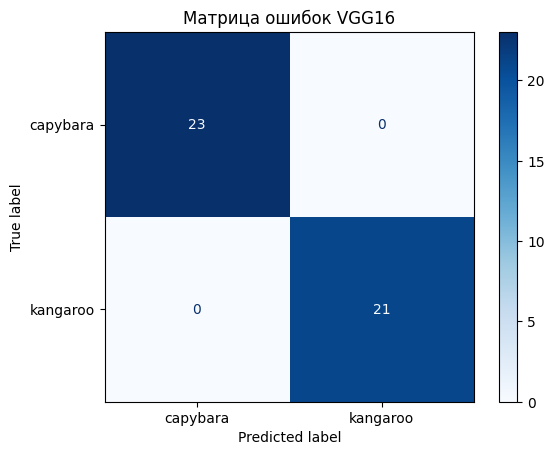

In [ ]:
# Строим матрицу ошибок
cm_vgg = confusion_matrix(y_true, y_pred_vgg)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_vgg,
    display_labels=class_names
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Матрица ошибок VGG16')
plt.show()

In [ ]:
# Создаём таблицу с результатами классификации
vgg_results = test_df.copy()

vgg_results['true_label'] = y_true
vgg_results['pred_label'] = y_pred_vgg
vgg_results['confidence'] = np.where(
    y_pred_vgg == 1,
    y_prob_vgg,
    1 - y_prob_vgg
)

# Оставляем только ошибочно классифицированные изображения
errors_vgg = vgg_results[
    vgg_results['true_label'] != vgg_results['pred_label']
].copy()

print(f'Всего ошибок VGG16: {len(errors_vgg)}')

# Показываем до 5 ошибок для каждого истинного класса
for class_id, class_name in enumerate(class_names):

    class_errors = errors_vgg[
        errors_vgg['true_label'] == class_id
    ].head(5)

    print(
        f'\nОшибки для класса "{class_name}": '
        f'{len(errors_vgg[errors_vgg["true_label"] == class_id])}'
    )

    if len(class_errors) == 0:
        print('Ошибок нет.')
        continue

    fig, axes = plt.subplots(
        1,
        len(class_errors),
        figsize=(4 * len(class_errors), 4)
    )

    if len(class_errors) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, class_errors.iterrows()):

        image = plt.imread(row['filepath'])
        ax.imshow(image)

        true_name = class_names[int(row['true_label'])]
        pred_name = class_names[int(row['pred_label'])]

        ax.set_title(
            f'Истинный: {true_name}\n'
            f'Предсказан: {pred_name}\n'
            f'Уверенность: {row["confidence"]:.2%}'
        )

        ax.axis('off')

    plt.tight_layout()
    plt.show()

Всего ошибок VGG16: 0

Ошибки для класса "capybara": 0
Ошибок нет.

Ошибки для класса "kangaroo": 0
Ошибок нет.


# Попробуем еще одну модель - YOLO

Документация: [YOLO12](https://docs.ultralytics.com/models/yolo12/),  [Обучение YOLO](https://docs.ultralytics.com/modes/train/), [Загрузка датасетов Roboflow](https://roboflow.github.io/roboflow-python/core/version/)

Здесь у нас будет интересный переход: от классификации изображений к обнаружению объектов (Object Detection).

До этого мы решали задачу: «Кто изображён на картинке — капибара или кенгуру?». Теперь будем решать более сложную задачу: «Есть ли на изображении капибара или кенгуру, где именно они находятся и сколько их?»

### Чем обнаружение объектов отличается от классификации?

В предыдущих экспериментах мы использовали классификацию изображений.

**Классификация:**

Один ответ на изображение
- Вход: изображение.
- Выход: класс и вероятность.

Например: капибара — 98%.

**Обнаружение объектов**

- Несколько объектов
- Вход: изображение.
- Выход: классы, координаты объектов и уверенность модели.

Например:
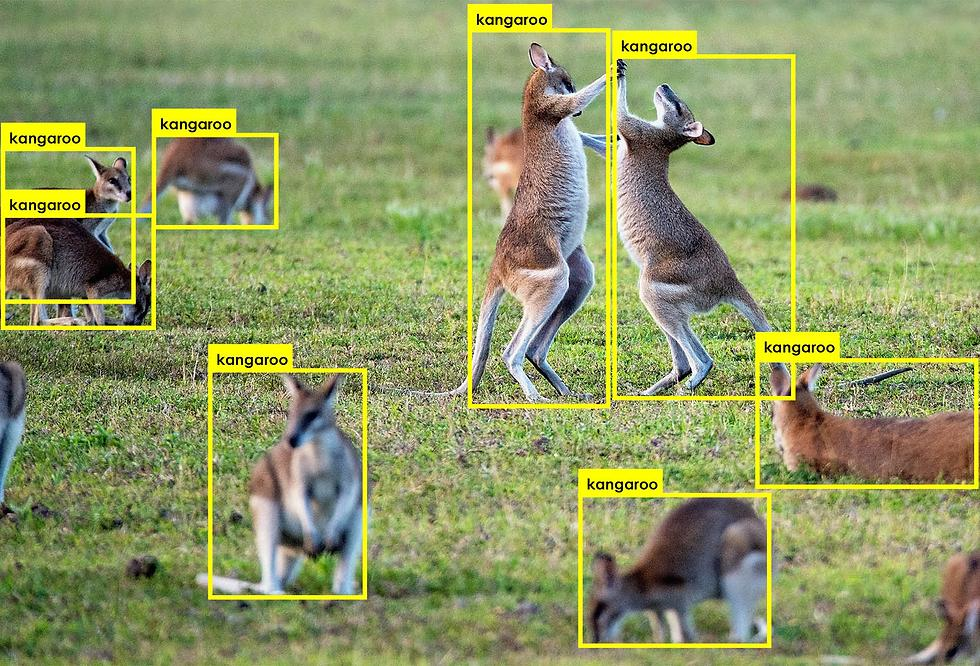

###  Что такое YOLO?

YOLO (You Only Look Once) — семейство нейросетевых моделей для обнаружения объектов на изображениях и видео.

Название отражает основную идею: модель анализирует изображение за один проход и сразу предсказывает расположение и классы объектов.

В отличие от нашей CNN, YOLO изначально предназначена не просто для классификации, а для поиска объектов на изображении.

Например, если на фотографии три капибары и два кенгуру, YOLO должна:
- обнаружить все пять объектов;
- определить класс каждого объекта;
- нарисовать вокруг каждого объекта ограничивающую рамку (Bounding Box);
- оценить уверенность каждого предсказания.

### Как YOLO определяет положение объектов?
Для каждого найденного объекта модель предсказывает несколько характеристик:

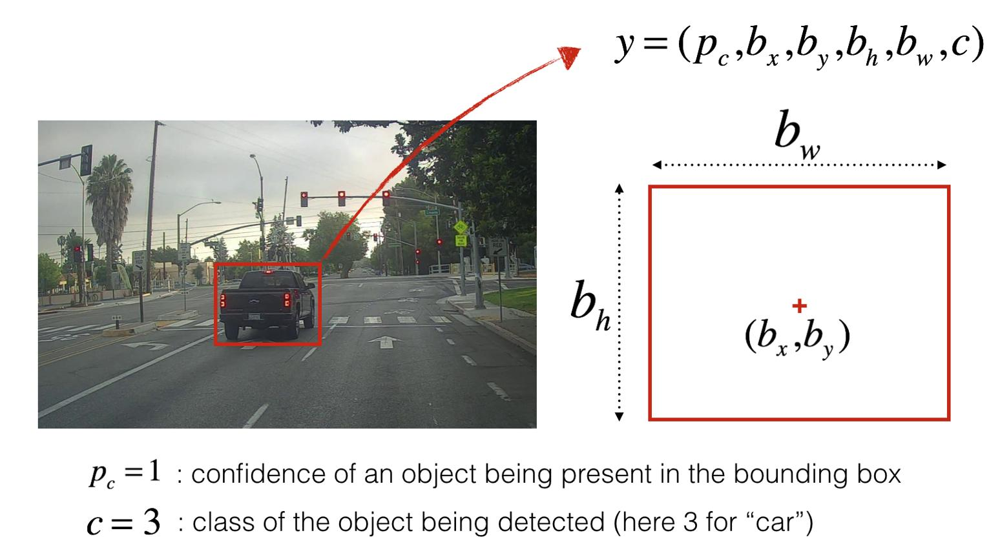

1. Bounding Box — прямоугольная рамка вокруг объекта.
2. Coordinates (x, y, w, h) — положение центра рамки и её ширина и высота.
3. Confidence — уверенность модели в обнаружении объекта и предсказании.
4. Class — класс объекта, например capybara или kangaroo.

## Установим YOLO

Будем использовать YOLO от Ultralytics и предварительно обученную модель yolo11n.pt — небольшую версию YOLO11.

Модель предварительно обучена на COCO, который содержит 80 классов объектов. Поэтому она не обязательно знает капибару как отдельный класс.

## You Only Look Ones (YOLO)

YOLO - это новейшее семейство моделей обнаружения объектов на базе YOLO от Ultralytics, обеспечивающих самые современные характеристики.

Основной принцип работы YOLO заключается в том, что он разбивает изображение на сетку и для каждой ячейки сетки предсказывает вероятности наличия различных классов объектов и координаты ограничивающей рамки для каждого объекта.

**Процесс работы YOLO можно разделить на несколько шагов**:

1. *Разделение изображения на сетку*

Сначала изображение разбивается на сетку с фиксированным количеством ячеек. Количество ячеек определяется параметрами алгоритма. Каждая ячейка будет отвечать за обнаружение объектов в своей области.

2. *Предсказание классов и координат*

Для каждой ячейки сетки алгоритм предсказывает вероятности наличия различных классов объектов. Например, если на изображении есть собака и автомобиль, то для каждой ячейки алгоритм предсказывает вероятности наличия собаки и автомобиля.

Кроме того, для каждого объекта алгоритм предсказывает координаты ограничивающей рамки, которая обрамляет объект. Это позволяет точно определить положение объекта на изображении.

3. *Фильтрация и уточнение предсказаний*

После предсказания классов и координат, алгоритм применяет фильтрацию для удаления низкопробных предсказаний и уточнения ограничивающих рамок. Например, если вероятность наличия объекта ниже определенного порога, то предсказание отбрасывается.

Также, для уточнения ограничивающих рамок, алгоритм использует методы регрессии, чтобы более точно определить положение объекта на изображении.

4. *Объединение предсказаний*

В конечном итоге, все предсказания для каждой ячейки сетки объединяются в один список, который содержит информацию о классах объектов и их координатах на изображении.

Таким образом, YOLO позволяет обнаруживать объекты на изображении в режиме реального времени, благодаря своей способности разбивать изображение на сетку и предсказывать классы и координаты для каждой ячейки.

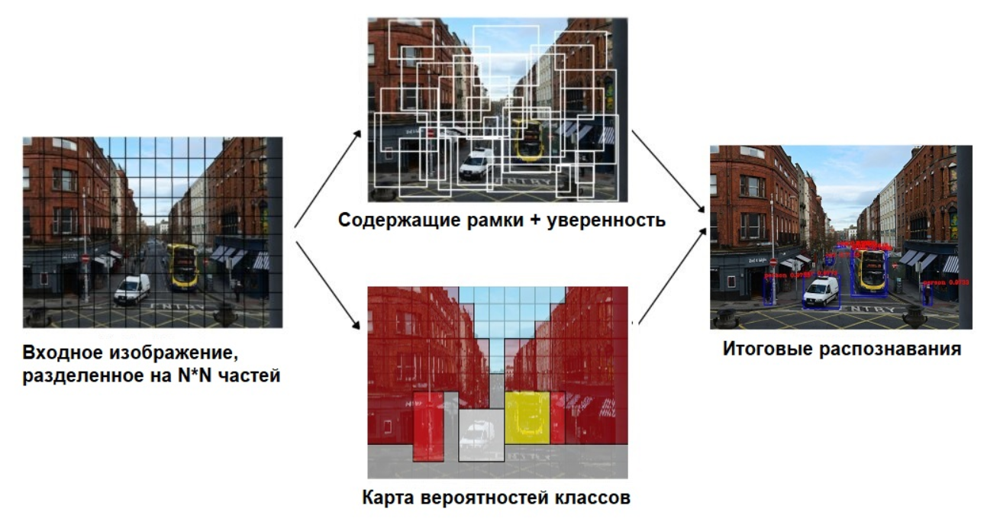

[Источник](https://proglib.io/p/raspoznavanie-obektov-s-pomoshchyu-yolo-v3-na-tensorflow-2-0-2020-11-08)

Подробная визуализация архитектуры этой сети [здесь](https://github.com/ultralytics/ultralytics/issues/189)



Модель YOLOv8 от Ultralitics уже предобучена на датасете COCO 2017 https://cocodataset.org/#home

Это популярный крупнейший в мире датасет для обучения моделей компьютерного зрения. Он состоит из более чем 330000 изображений (220000 — размеченных), с более чем 1.5 милионов объектов на них.

Все объекты находятся в их естественном окружении (контексте). Изображения, как правило, содержат объекты разных классов (только 10% имеют единственный класс). Все изображения сопровождаются аннотациями, хранящихся в json формате.

Официально этот датасет содержит 80 класс объектов, их описание можно найти [здесь](https://github.com/amikelive/coco-labels/blob/master/coco-labels-2014_2017.txt)

Пример изображений из этого набора:

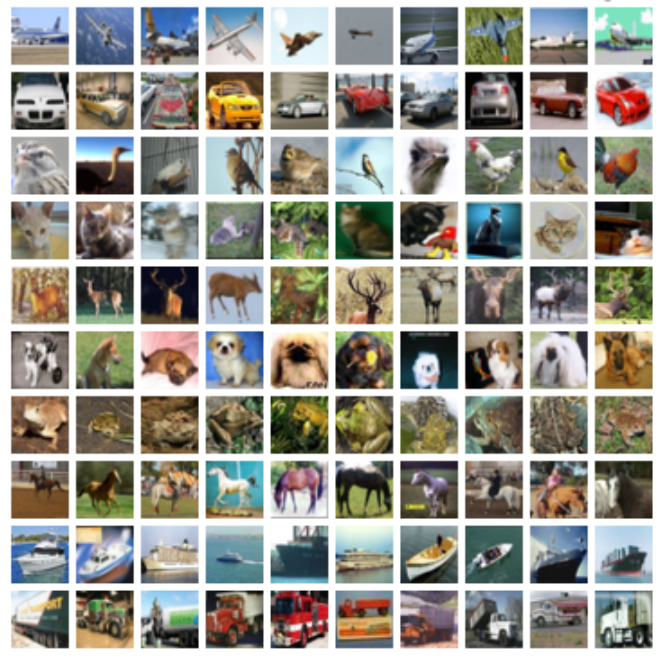

[Источник](https://cocodataset.org/)



In [ ]:
!pip install -q ultralytics

from ultralytics import YOLO

# Загружаем предобученную YOLO11n.
# При первом запуске веса модели скачаются автоматически.
yolo_model = YOLO('yolo11n.pt')

Возьмём по одному случайному изображению из тестовой выборки. Зафиксируем random_state, чтобы при повторном запуске выбирать те же изображения.

In [ ]:
# Выбираем по одному изображению каждого класса
capybara_row = test_df[test_df['label'] == 0].sample(
    n=1, random_state=42
).iloc[0]

kangaroo_row = test_df[test_df['label'] == 1].sample(
    n=1, random_state=42
).iloc[0]

selected_images = [
    (capybara_row['filepath'], 'capybara'),
    (kangaroo_row['filepath'], 'kangaroo')
]

for filepath, class_name in selected_images:
    print(f'{class_name}: {filepath}')

capybara: /content/drive/MyDrive/IDlab/машинное_обучение/data_sem_9/capybara/Capybara_302.jpg
kangaroo: /content/drive/MyDrive/IDlab/машинное_обучение/data_sem_9/kangaroo/Kangaroo_80.jpg



Истинный класс изображения: capybara


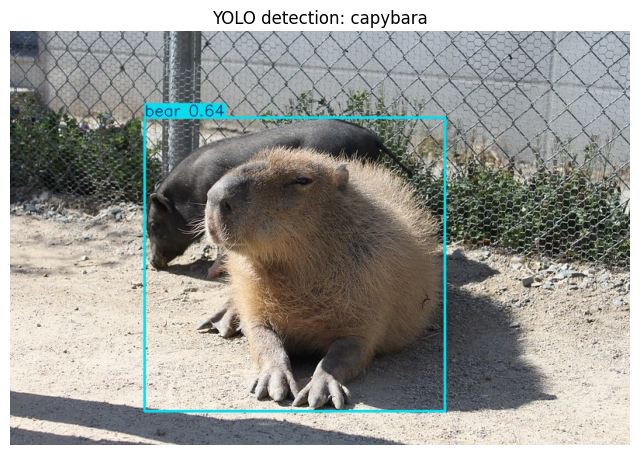

Обнаружен объект: bear, уверенность: 64.40%

Истинный класс изображения: kangaroo


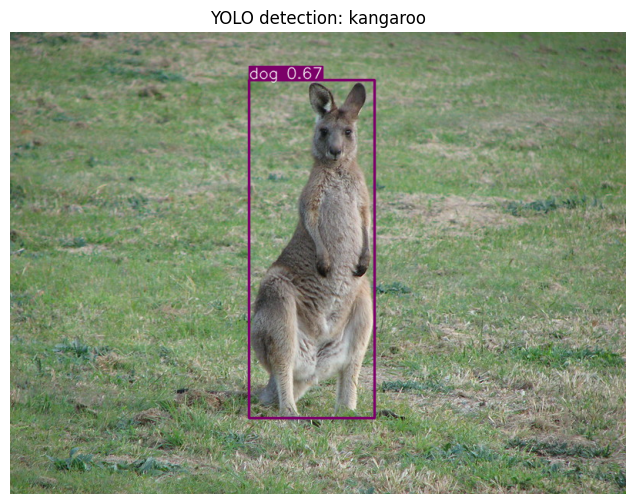

Обнаружен объект: dog, уверенность: 67.20%


In [ ]:
# Передаём два изображения в YOLO
for filepath, true_class in selected_images:

    print(f'\nИстинный класс изображения: {true_class}')

    # Выполняем обнаружение объектов
    results = yolo_model.predict(
        source=filepath,
        conf=0.25,
        verbose=False
    )

    # Получаем результат для текущего изображения
    result = results[0]

    # Отображаем изображение с найденными объектами и рамками
    plt.figure(figsize=(8, 6))
    plt.imshow(result.plot()[..., ::-1])  # BGR -> RGB
    plt.title(f'YOLO detection: {true_class}')
    plt.axis('off')
    plt.show()

    # Выводим информацию о найденных объектах
    if len(result.boxes) == 0:
        print('Объекты не обнаружены.')
    else:
        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())
            class_name = yolo_model.names[class_id]

            print(
                f'Обнаружен объект: {class_name}, '
                f'уверенность: {confidence:.2%}'
            )

Да, для нейросети в этом случае кенгуру тоже похож на собаку, а капибара на медведя

Так происходит потому, что в датасете, на котором предобучена нейросеть не было ни капибары, ни кенгуру.

Допустим, у нас задача именно научиться распознавать этих животных. Тогда нам необходимо **доучить** нейросеть на небольшой выборке изображений капибары и кенгуру, чтобы нейросеть научилась их находить.


Для того, чтобы доучить нейросеть, нам потребуется не только найти изображения, но и **разметить**, т.е. указать в специальном формате нейросети, где именно на изображении находится ограничивающая рамка с изображением искомого животного.

Для того, чтобы это сделать, мы используем специальный инструмент Roboflow https://app.roboflow.com/

*(Для выполнения этого задания, Вам необходимо будет зарегистрироваться на робофлоу и создать свой датасет)*

Размеченный датасет с семинарского занятия можно посмотреть [тут](https://universe.roboflow.com/hse-ttabc/hse_sem15_animals)

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="lcneOu2fzeKVwDxiMd7b")
project = rf.workspace("hse-ttabc").project("hse_sem15_animals")
version = project.version(2)
dataset = version.download("yolov12")


loading Roboflow workspace...
loading Roboflow project...


### Что внутри нашего датасета

In [ ]:
import os
import yaml

# Путь к конфигурации датасета
data_yaml = os.path.join(dataset.location, 'data.yaml')

# Загружаем конфигурацию
with open(data_yaml, 'r') as file:
    data_config = yaml.safe_load(file)

print('Путь к датасету:', dataset.location)
print('\nКлассы:', data_config['names'])
print('\nКоличество классов:', data_config['nc'])

print('\nРазделение датасета:')
print('Train:', data_config['train'])
print('Validation:', data_config['val'])
print('Test:', data_config.get('test', 'Не задан'))

Путь к датасету: /content/HSE_sem15_animals-2

Классы: ['capybara', 'kangaroo']

Количество классов: 2

Разделение датасета:
Train: ../train/images
Validation: ../valid/images
Test: ../test/images


### Дообучаем модель распознавать капибар и кенгуру

In [ ]:
!pip install -q -U ultralytics

from ultralytics import YOLO

# Загружаем предобученную YOLO12n
model = YOLO('yolo12n.pt')

# Дообучаем модель на нашем датасете
results = model.train(
    data=data_yaml,       # Конфигурация датасета
    epochs=50,            # Максимальное количество эпох
    imgsz=640,            # Размер изображений
    batch=16,             # Размер батча
    patience=10,          # Остановка при отсутствии улучшений
    seed=42,              # Фиксируем случайность
    plots=True            # Сохраняем графики обучения
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/HSE_sem15_animals-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=Fa

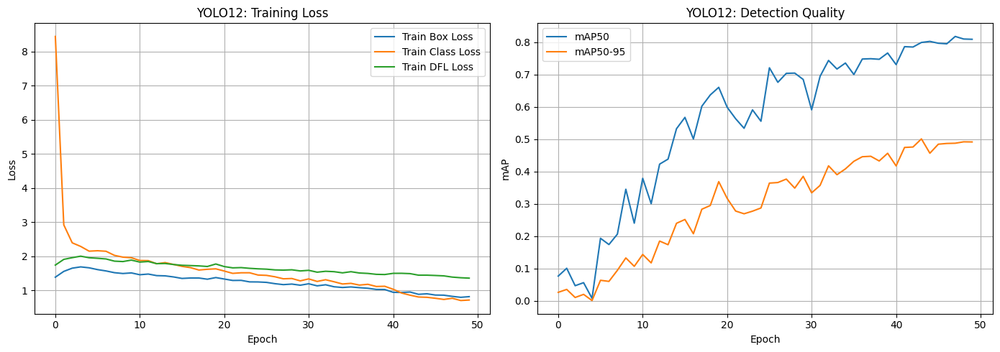

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Получаем путь к CSV с историей обучения
results_path = os.path.join(
    results.save_dir,
    'results.csv'
)

# Загружаем историю обучения
history_yolo = pd.read_csv(results_path)

# Убираем пробелы в названиях столбцов
history_yolo.columns = history_yolo.columns.str.strip()

# Создаём два графика
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График Loss
axes[0].plot(
    history_yolo['train/box_loss'],
    label='Train Box Loss'
)
axes[0].plot(
    history_yolo['train/cls_loss'],
    label='Train Class Loss'
)
axes[0].plot(
    history_yolo['train/dfl_loss'],
    label='Train DFL Loss'
)

axes[0].set_title('YOLO12: Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid()

# График mAP
axes[1].plot(
    history_yolo['metrics/mAP50(B)'],
    label='mAP50'
)
axes[1].plot(
    history_yolo['metrics/mAP50-95(B)'],
    label='mAP50-95'
)

axes[1].set_title('YOLO12: Detection Quality')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('mAP')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

### Левый график — Training Loss
Потери модели на обучающей выборке. Чем ниже значения, тем лучше.

Здесь три компонента функции потерь.

1. Train Box Loss — ошибка локализации объекта

Показывает, насколько предсказанные рамки (bounding boxes) отличаются от правильных рамок в разметке.

Например, если на изображении капибара, модель должна нарисовать рамку, которая максимально точно охватывает её тело.
- Большое значение — рамки пока плохо совпадают с правильными.
- Маленькое значение — модель точнее определяет границы объектов.

2. Train Class Loss — ошибка классификации

Показывает, насколько правильно модель определяет класс найденного объекта.

В нашей задаче это:
- capybara;
- kangaroo.

Например, если на изображении кенгуру, а модель определяет его как капибару, возникает ошибка классификации.

3. Train DFL Loss — Distribution Focal Loss

Это дополнительная составляющая функции потерь, используемая YOLO для более точного определения координат границ объектов.

Если говорить проще, она помогает модели точнее предсказывать положение и размеры bounding box.

Что видно на нашем графике?
- Box Loss постепенно снижается примерно с 1,4 до 0,8.
- Class Loss существенно снижается примерно с 8,4 до 0,7.
- DFL Loss снижается примерно с 1,75 до 1,35.

Это говорит о том, что модель постепенно учится лучше локализовать объекты и определять их классы.

Важно: значения трёх Loss нельзя напрямую сравнивать между собой. У них разные способы расчёта и масштабы.

### Правый график — Detection Quality
Метрики качества обнаружения объектов. Чем выше значения, тем лучше.

Здесь две метрики.

1. mAP50 — Mean Average Precision при IoU = 0.5

Это средняя точность обнаружения объектов по классам при условии, что предсказанная рамка достаточно хорошо совпадает с правильной.

Для понимания сначала разберём IoU.

IoU (Intersection over Union) — отношение площади пересечения двух рамок к площади их объединения.

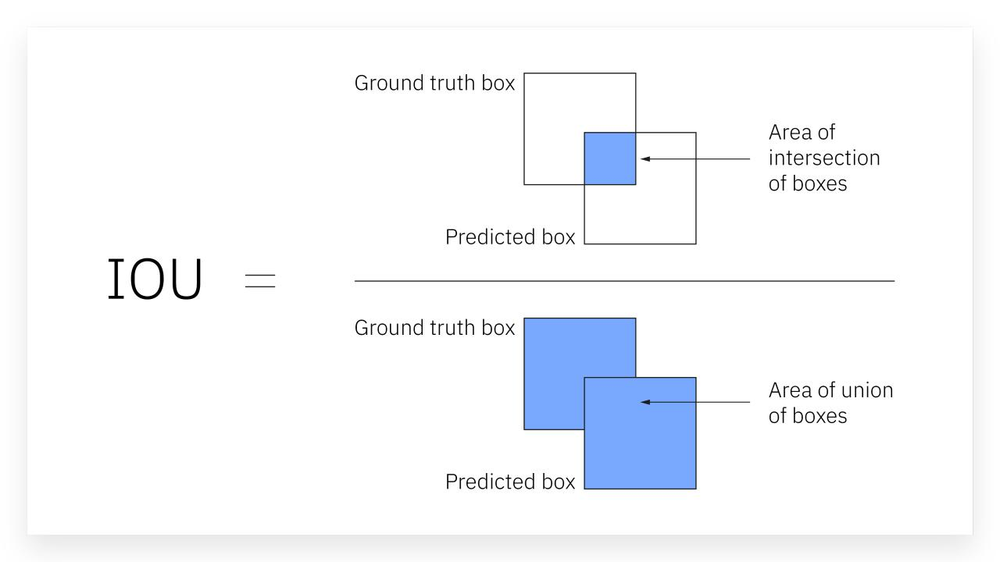

Если IoU не меньше 0,5, обнаружение считается достаточно точным для этого порога.

Значение mAP50 учитывает качество Precision-Recall по каждому классу и усредняет Average Precision между классами.

У нас итоговое значение приблизительно 0,81.

2. mAP50-95 — Mean Average Precision при IoU от 0.5 до 0.95

Это более строгая метрика.

В отличие от mAP50, здесь качество оценивается при нескольких порогах IoU: от 0,5 до 0,95 с шагом 0,05.

То есть модель должна не просто найти правильный объект, но и достаточно точно определить его границы.

У нас итоговое значение приблизительно 0,49.

### Качество лучшей модели

In [ ]:
# Загружаем лучшую версию обученной модели
best_model = YOLO(
    'runs/detect/train/weights/best.pt'
)

# Оцениваем качество на тестовой выборке
test_results = best_model.val(
    data=data_yaml,
    split='test'
)

print('Оценка на тестовой выборке:')
print(f'mAP50:    {test_results.box.map50:.4f}')
print(f'mAP50-95: {test_results.box.map:.4f}')

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 160 layers, 2,571,870 parameters, 0 gradients, 7.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 303.2±132.3 MB/s, size: 9.7 KB)
val: Scanning /content/HSE_sem15_animals-2/test/labels.cache... 41 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 41/41 10.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.0it/s 1.5s
                   all         41         61      0.752      0.623       0.71      0.474
              capybara         27         37      0.874      0.676      0.815      0.556
              kangaroo         14         24      0.631       0.57      0.605      0.391
Speed: 3.7ms preprocess, 7.5ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to /content/runs/detect/val-3
Оценка на тестовой выборке:
mAP50:    0.7100
mAP50-95: 0.4737


### Смотрим результат

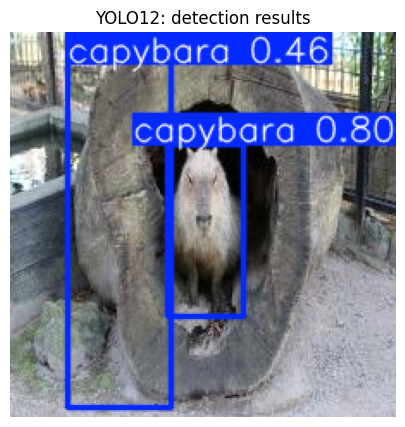

capybara: 79.51%
capybara: 46.26%


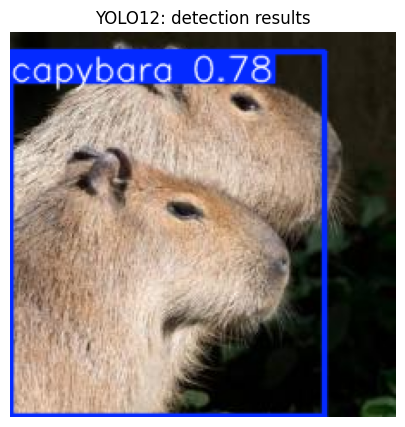

capybara: 77.85%


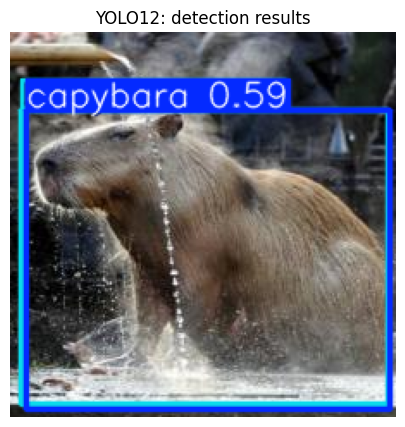

capybara: 59.26%
kangaroo: 25.22%


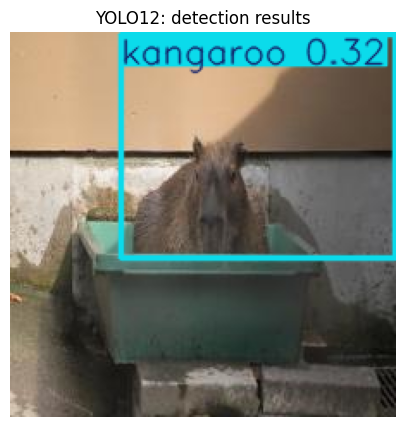

kangaroo: 32.39%


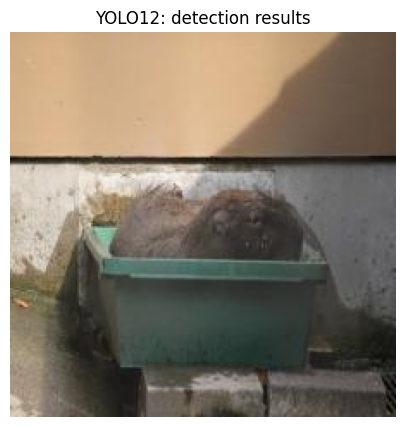

Объекты не обнаружены.


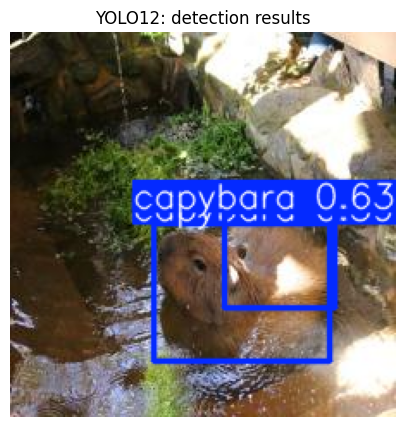

capybara: 62.61%
capybara: 59.36%


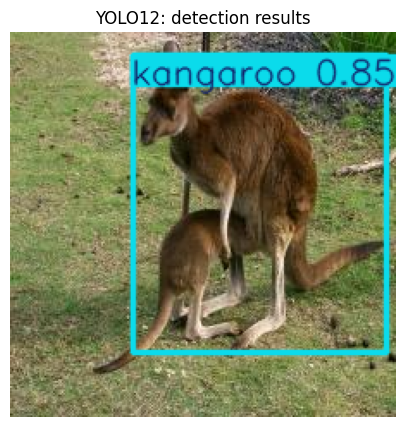

kangaroo: 85.43%


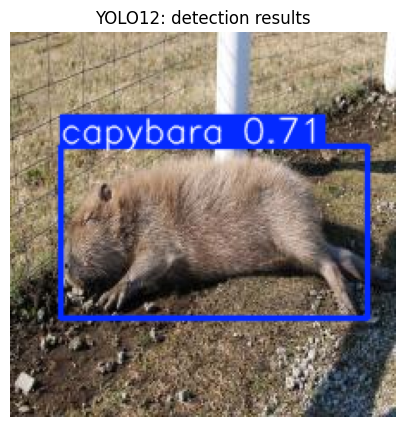

capybara: 70.54%


In [ ]:
import glob
import random
import matplotlib.pyplot as plt

# Получаем путь к тестовым изображениям
test_dir = os.path.join(dataset.location, 'test', 'images')

# Находим изображения
test_images = glob.glob(
    os.path.join(test_dir, '*.*')
)

# Выбираем случайные изображения для демонстрации
random.seed(42)
selected_images = random.sample(
    test_images,
    min(8, len(test_images))
)

# Запускаем распознавание
predictions = best_model.predict(
    source=selected_images,
    conf=0.25,
    verbose=False
)

# Выводим результаты
for result in predictions:

    # Рисуем рамки и названия классов
    image = result.plot()

    plt.figure(figsize=(7, 5))
    plt.imshow(image[..., ::-1])  # BGR -> RGB
    plt.title('YOLO12: detection results')
    plt.axis('off')
    plt.show()

    # Выводим обнаруженные объекты
    if len(result.boxes) == 0:
        print('Объекты не обнаружены.')
    else:
        for box in result.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())
            class_name = best_model.names[class_id]

            print(
                f'{class_name}: '
                f'{confidence:.2%}'
            )

### Теперь давайте через нашу модель попробуем прогнать изображение медведя

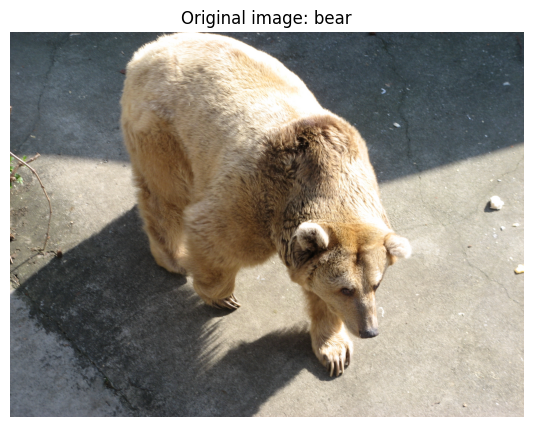

In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# Ссылка на оригинальную фотографию с Wikimedia Commons
image_url = (
    'https://commons.wikimedia.org/wiki/'
    'Special:Redirect/file/Brown-bear.jpg'
)

# Загружаем изображение
response = requests.get(
    image_url,
    headers={'User-Agent': 'Mozilla/5.0'}
)
response.raise_for_status()

# Сохраняем изображение
bear_path = '/content/bear.jpg'

with open(bear_path, 'wb') as f:
    f.write(response.content)

# Показываем исходное изображение
bear_image = Image.open(bear_path)

plt.figure(figsize=(8, 5))
plt.imshow(bear_image)
plt.title('Original image: bear')
plt.axis('off')
plt.show()

Классы модели: {0: 'capybara', 1: 'kangaroo'}


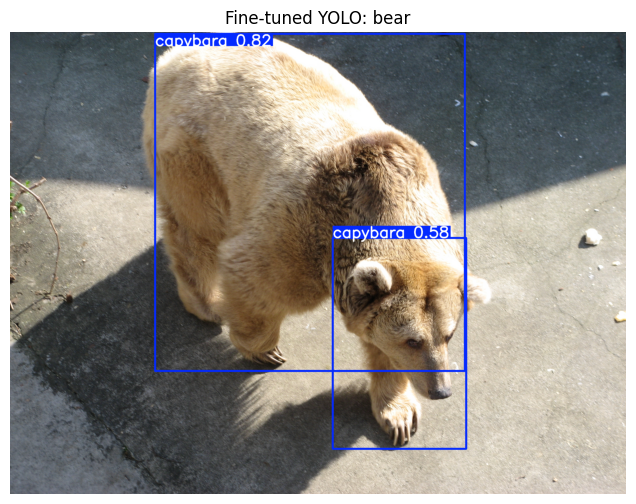

Обнаружен объект: capybara, уверенность: 82.48%
Обнаружен объект: capybara, уверенность: 58.01%


In [ ]:
# Посмотрим, какие классы знает наша модель
print('Классы модели:', best_model.names)

# Запускаем обнаружение объектов
results = best_model.predict(
    source=bear_path,
    conf=0.25,
    verbose=False
)

result = results[0]

# Отображаем результат
plt.figure(figsize=(9, 6))
plt.imshow(result.plot()[..., ::-1])
plt.title('Fine-tuned YOLO: bear')
plt.axis('off')
plt.show()

# Выводим предсказания
if len(result.boxes) == 0:
    print('Объекты не обнаружены.')
else:
    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        class_name = best_model.names[class_id]

        print(
            f'Обнаружен объект: {class_name}, '
            f'уверенность: {confidence:.2%}'
        )

## Задание: https://disk.360.yandex.ru/i/UmwONp5pJ9SaJA

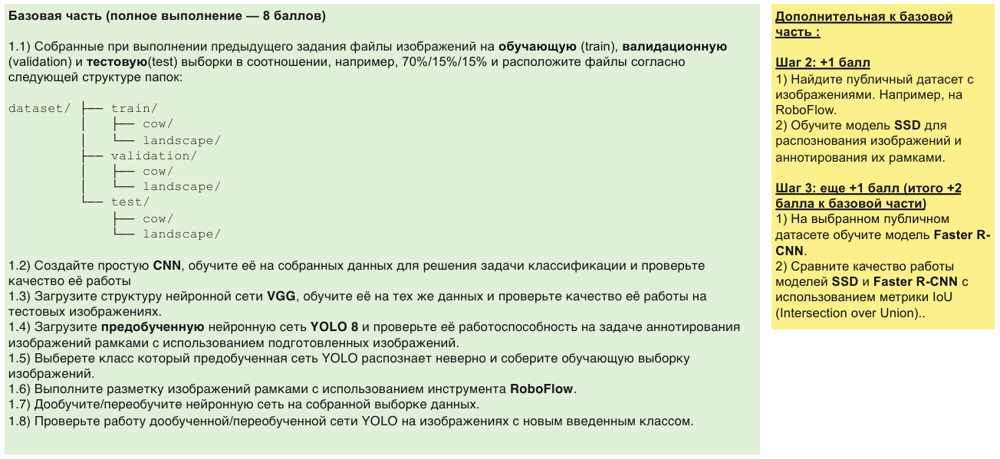